In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [6]:
df=pd.read_csv("Telco_Customer_Churn.csv")

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
df.shape

(7043, 21)

In [10]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [15]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [16]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [17]:
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [18]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [19]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [20]:
df.dropna(subset=['TotalCharges'],inplace=True)

In [21]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [22]:
churn_count=df['Churn'].value_counts()
total_customers=len(df)
churn_rate=(churn_count['Yes']/total_customers)*100
print("Total Customers:",total_customers)
print("Churned Customers",churn_count['Yes'])
print("Overall Churn Rate:",round(churn_rate,2),"%")

Total Customers: 7032
Churned Customers 1869
Overall Churn Rate: 26.58 %


In [23]:
bins=[0,12,24,36,48,60,72]
labels=['0-12','13-24','25-36','37-48','49-60','61-72']
df['TenureGroup']=pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [24]:
df['TenureGroup'].value_counts().sort_index()

TenureGroup
0-12     2175
13-24    1024
25-36     832
37-48     762
49-60     832
61-72    1407
Name: count, dtype: int64

In [26]:
tenure_churn=df.groupby(
    'TenureGroup',
    observed=False
)['Churn'].apply(
lambda x:(x=='Yes').mean()*100
)
print(tenure_churn.round(2))

TenureGroup
0-12     47.68
13-24    28.71
25-36    21.63
37-48    19.03
49-60    14.42
61-72     6.61
Name: Churn, dtype: float64


In [30]:
contract_churn=df.pivot_table(
    index='Contract',
    columns='Churn',
    values='customerID',
    aggfunc='count',
    fill_value=0
)
contract_churn['Churn Rate(%)']=(
    contract_churn['Yes']/
    (
        contract_churn['Yes']+
        contract_churn['No']
    ))*100
contract_churn

Churn,No,Yes,Churn Rate(%)
Contract,,,
Month-to-month,2220,1655,42.709677
One year,1306,166,11.277174
Two year,1637,48,2.848665


In [31]:
payment_churn=df.pivot_table(
    index='PaymentMethod',
    columns='Churn',
    values='customerID',
    aggfunc='count',
    fill_value=0
)
payment_churn['Churn Rate(%)']=(
    payment_churn['Yes']/
    (
        payment_churn['Yes']+
        payment_churn['No']
    ))*100
payment_churn

Churn,No,Yes,Churn Rate(%)
PaymentMethod,,,
Bank transfer (automatic),1284,258,16.731518
Credit card (automatic),1289,232,15.253123
Electronic check,1294,1071,45.285412
Mailed check,1296,308,19.201995


In [36]:
high_risk=df[
    (df['tenure']<=12)&
    (df['MonthlyCharges']>
df['MonthlyCharges'].median())&
    (df['Churn']=='Yes')
]
print("High-Risk Customers:",
len(high_risk))
high_risk.head()

High-Risk Customers: 571


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,0-12
39,8168-UQWWF,Female,0,No,No,11,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),97.85,1105.40,Yes,0-12
47,7760-OYPDY,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,Yes,No,Month-to-month,Yes,Electronic check,80.65,144.15,Yes,0-12
53,7495-OOKFY,Female,1,Yes,No,8,Yes,Yes,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Credit card (automatic),80.65,633.30,Yes,0-12


In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [12]:
import os
os.listdir()

['.ipynb_checkpoints',
 '21 Creative Uni Bedroom Decor Ideas for 2024 - Copy.webp',
 '21 Creative Uni Bedroom Decor Ideas for 2024.webp',
 '3018.pptx',
 '59b3560180b4fd4b2e284155d3ae1a82 (1).xapk',
 '59b3560180b4fd4b2e284155d3ae1a82.xapk',
 'Advanced Excel with AI Project Statement (1).pdf',
 'Advanced Excel with AI Project Statement.pdf',
 'Advanced Excel with AI Training - Certificate of Completion.pdf',
 'Advanced_Excel Project Dataset.zip',
 'Anaconda3-2026.07-1-Windows-x86_64.exe',
 'Assignment Solution_Module 2.zip',
 'Basic_Formulas_-_Mini_Challenge.xlsx',
 'Biryani - Copy.jpg',
 'Biryani.jpg',
 'Charts_Mini_Challenge.xlsx',
 'ChatGPT - Search.html',
 'ChatGPT - Search_files',
 'ChromeStandaloneSetup64.exe',
 'Cleaned_Sales_Data (1).csv',
 'Cleaned_Sales_Data.csv',
 'clothing rack - Copy.webp',
 'clothing rack.webp',
 'COCKTAIL - Copy.jpg',
 "Cocktail Starring_Deepika Padukone,Saif Ali Khan,Tina Desai 2012 Movie IMDb_6_1 Actually a fun movie. Deepika's performance is wonderful _

In [14]:
df = pd.read_csv('telco_customer_churn.csv')

In [15]:
df.shape

(7043, 21)

In [18]:
high_risk=df[
    (df['tenure']<=12)&
    (df['MonthlyCharges']>
     df['MonthlyCharges'].median())&
    (df['Churn']=='Yes')
    ]
print("High-Risk Customers:",len(high_risk))
high_risk.head()

High-Risk Customers: 571


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
39,8168-UQWWF,Female,0,No,No,11,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),97.85,1105.4,Yes
47,7760-OYPDY,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,80.65,144.15,Yes
53,7495-OOKFY,Female,1,Yes,No,8,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),80.65,633.3,Yes


In [19]:
bins=[0,12,24,36,48,60,72]
labels=['0-12','13-24','25-36','37-48','49-60','61-72']

df['TenureGroup']=pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

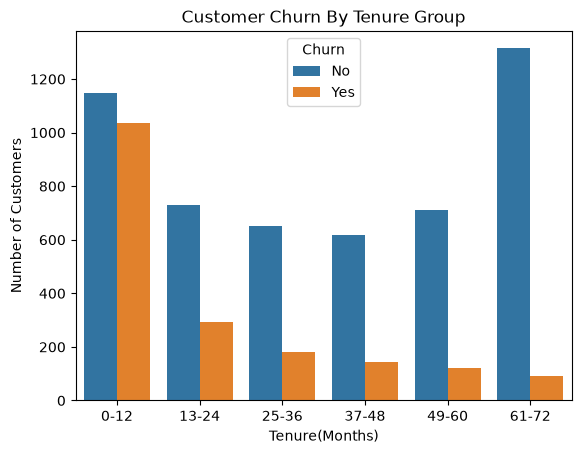

In [20]:
sns.countplot(
    data=df,
    x='TenureGroup',
    hue='Churn'
)
plt.title('Customer Churn By Tenure Group')
plt.xlabel('Tenure(Months)')
plt.ylabel('Number of Customers')
plt.show()

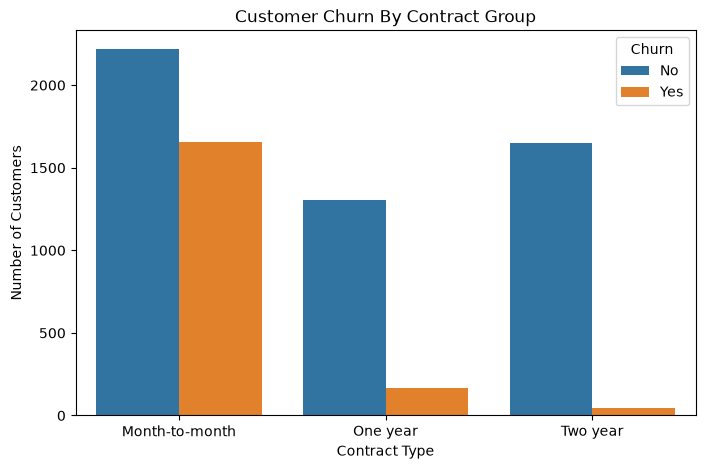

In [23]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)
plt.title('Customer Churn By Contract Group')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

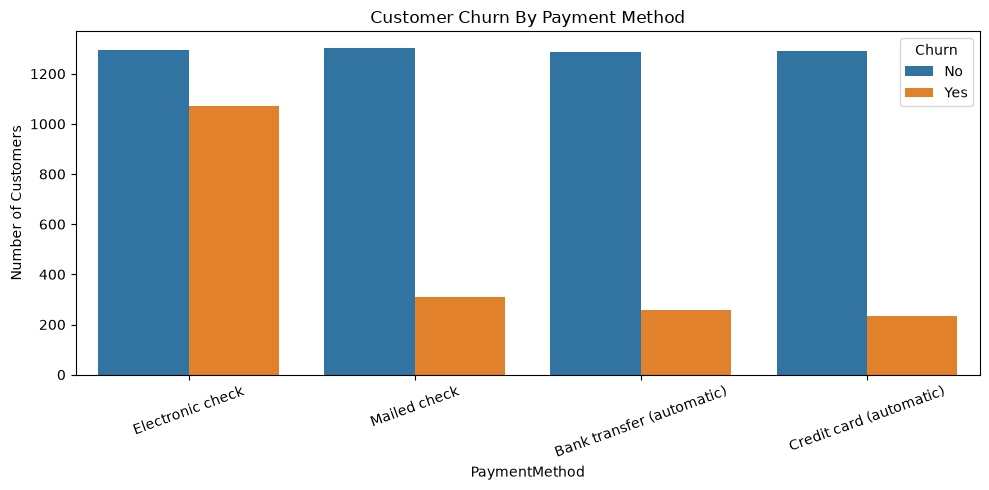

In [26]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)
plt.title('Customer Churn By Payment Method')
plt.xlabel('PaymentMethod')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [27]:
df['Retained']=(df['Churn']=='No').astype(int)

In [29]:
retention_matrix=df.pivot_table(
    index='TenureGroup',
    columns='Contract',
    values='Retained',
    aggfunc='mean'
)*100
retention_matrix.round(2)

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-12,48.65,89.52,100.00
13-24,62.28,91.88,100.00
25-36,67.49,92.00,97.92
37-48,66.46,86.94,97.75
49-60,72.22,86.29,96.03
61-72,77.78,87.86,96.86


In [38]:
contract_churn=pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
)*100
contract_churn['Churn Rate(%)'] =contract_churn['Yes']
contract_churn

Churn,No,Yes,Churn Rate(%)
Contract,,,
Month-to-month,57.290323,42.709677,42.709677
One year,88.730482,11.269518,11.269518
Two year,97.168142,2.831858,2.831858


In [40]:
payment_churn=pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
)*100
payment_churn['Churn Rate(%)']=payment_churn['Yes']
payment_churn

Churn,No,Yes,Churn Rate(%)
PaymentMethod,,,
Bank transfer (automatic),83.290155,16.709845,16.709845
Credit card (automatic),84.756899,15.243101,15.243101
Electronic check,54.714588,45.285412,45.285412
Mailed check,80.893300,19.106700,19.106700


In [45]:
tenure_churn=pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
)*100
tenure_churn['Churn Rate(%)'] = tenure_churn['Yes']
print(tenure_churn.round(2))

Churn           No    Yes  Churn Rate(%)
TenureGroup                             
0-12         52.56  47.44          47.44
13-24        71.29  28.71          28.71
25-36        78.37  21.63          21.63
37-48        80.97  19.03          19.03
49-60        85.58  14.42          14.42
61-72        93.39   6.61           6.61


In [37]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup', 'Retained']


In [46]:
print("CUSTOMER CHURN ANALYSIS REPORT")
print("="*40)

print("Total Customers:", len(df))
print("Churned Customers:", (df['Churn']=='Yes').sum())

print("Overall Churn Rate:",
      round((df['Churn']=='Yes').mean()*100, 2), "%")

print("\nChurn by Contract:")
print(contract_churn.round(2))

print("\nChurn by Payment Method:")
print(payment_churn.round(2))

print("\nChurn by Tenure Group:")
print(tenure_churn.round(2))

CUSTOMER CHURN ANALYSIS REPORT
Total Customers: 7043
Churned Customers: 1869
Overall Churn Rate: 26.54 %

Churn by Contract:
Churn           No    Yes
TenureGroup              
0-12         52.56  47.44
13-24        71.29  28.71
25-36        78.37  21.63
37-48        80.97  19.03
49-60        85.58  14.42
61-72        93.39   6.61

Churn by Payment Method:
Churn                         No    Yes  Churn Rate(%)
PaymentMethod                                         
Bank transfer (automatic)  83.29  16.71          16.71
Credit card (automatic)    84.76  15.24          15.24
Electronic check           54.71  45.29          45.29
Mailed check               80.89  19.11          19.11

Churn by Tenure Group:
Churn           No    Yes  Churn Rate(%)
TenureGroup                             
0-12         52.56  47.44          47.44
13-24        71.29  28.71          28.71
25-36        78.37  21.63          21.63
37-48        80.97  19.03          19.03
49-60        85.58  14.42          14.42


In [49]:
# Business Recommendations

print("1. Encourage customers to choose long-term contracts.2. Improve customer support for new customers.")
print("3. Offer loyalty benefits to reduce customer churn. 4. Review pricing plans for customers paying higher monthly charges.")
print("5. Improve payment experience and customer satisfaction.")

# Conclusion

print("The analysis identifies customer churn patterns based on tenure, contract type, and payment methods.")
print("These insights can help the company improve customer retention and reduce churn through targeted strategies.")


1. Encourage customers to choose long-term contracts.2. Improve customer support for new customers.
3. Offer loyalty benefits to reduce customer churn. 4. Review pricing plans for customers paying higher monthly charges.
5. Improve payment experience and customer satisfaction.
The analysis identifies customer churn patterns based on tenure, contract type, and payment methods.
These insights can help the company improve customer retention and reduce churn through targeted strategies.
